<a href="https://colab.research.google.com/github/JaquelinedeJesus/Simulaci-n-2/blob/main/Modelo%20SIR%20con%20pyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Modelo SIR con pyMC**

**Alumna:** Jaqueline de Jesús Espinoza Cano

## **Objetivo:**

Implementar inferencia bayesiana utilizando Python y la librería PyMC. El modelo SIR se formula mediante ecuaciones diferenciales discretas, y se define una verosimilitud de Poisson para los conteos observados. A través del muestreo MCMC (Markov Chain Monte Carlo), para obtener las distribuciones posteriores de $a$ y $b$.

## **Problema:**

Se requiere estimar los parámetros de transmisión $a$ y recuperación $b$ de un brote epidémico modelado mediante el esquema SIR. Dado que los datos observados (conteos diarios de infectados) son discretos y presentan ruido, los métodos tradicionales de ajuste no capturan adecuadamente la incertidumbre.


## **Método:**

Se importan las herramientas necesarias para el cálculo numérico, la definición del modelo probabilístico y la visualización. Se definen los datos observados del brote.

,Día,Infectados observados
0,0,1
1,1,3
2,2,6
3,3,25
4,4,73
5,5,222
6,6,294
7,7,258
8,8,237
9,9,191


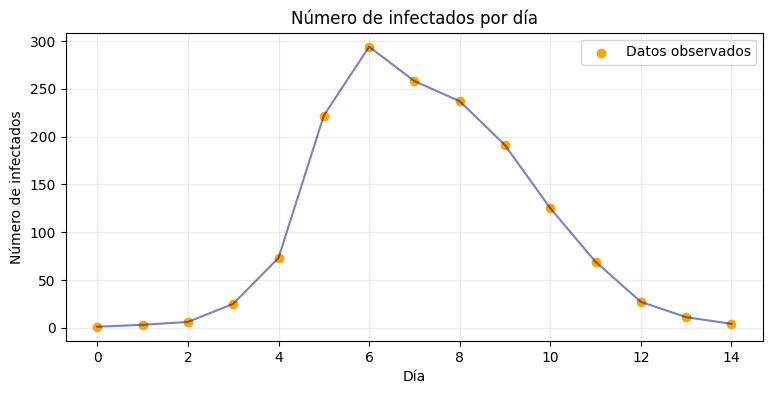

In [7]:
# IMPORTACIÓN DE LIBRERÍAS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm                           # Modelado probabilístico bayesiano y MCMC
import pytensor
import pytensor.tensor as pt
import arviz as az                          # Análisis y diagnóstico de muestras MCMC

# DEFINICIÓN DE PARÁMETROS DEL MODELO Y DATOS

# Población total y condiciones iniciales del modelo SIR
N = 763          # Población total
S0 = 762         # Número inicial de personas susceptibles (N - I0 - R0)
I0 = 1           # Número inicial de personas infectadas
R0 = 0           # Número inicial de personas recuperadas

# Días de observación
dias = np.arange(15)

# Conteos diarios de infectados observados durante el brote
I_datos = np.array([
    1, 3, 6, 25, 73,
    222, 294, 258, 237, 191,
    125, 69, 27, 11, 4
])

# ORGANIZACIÓN Y VISUALIZACIÓN DE DATOS

datos = pd.DataFrame({
    "Día": dias,
    "Infectados observados": I_datos
})

display(datos)

# Graficar los datos observados
plt.figure(figsize=(9, 4))
plt.scatter(dias, I_datos, color="orange", label="Datos observados")
plt.plot(dias, I_datos, color="darkblue", alpha=0.5)
plt.title("Número de infectados por día")
plt.xlabel("Día")
plt.ylabel("Número de infectados")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

# **Formulación del Modelo SIR**

El modelo SIR divide la población en tres compartimentos: Susceptibles $S$, Infectados $I$ y Recuperados $R$. La población total se conserva: $S(t) + I(t) + R(t) = N$. La dinámica se describe mediante el siguiente sistema de ecuaciones diferenciales:

\begin{align*}
\frac{dS}{dt} &= -aSI \\
\frac{dI}{dt} &= aSI - bI \\
\frac{dR}{dt} &= bI
\end{align*}

Donde $a$ es la tasa de transmisión y $b$ es la tasa de recuperación.

Se discretiza el tiempo en pasos de $dt = 0.1$ días. Se utiliza pytensor.scan para iterar las ecuaciones diferenciales a lo largo del tiempo.

In [16]:
# Variables necesarias definidas previamente
S0 = 762
I0 = 1
R0 = 0

# DEFINICIÓN DE LA DISCRETIZACIÓN TEMPORAL

dt = 0.1
pasos_por_dia = 10
n_pasos = 14 * pasos_por_dia

# CONSTRUCCIÓN DEL MODELO BAYESIANO EN PYMC
with pm.Model() as modelo_sir:

    # 1. DISTRIBUCIONES PREVIAS (PRIORS) DE LOS PARÁMETROS

    a = pm.LogNormal(
        "a",
        mu=np.log(0.002),
        sigma=0.25
    )

    b = pm.LogNormal(
        "b",
        mu=np.log(0.43),
        sigma=0.25
    )

    # 2. DEFINICIÓN DE UN PASO DEL MODELO SIR

    def paso_sir(indice, S_ant, I_ant, R_ant, a, b):

        contagios = a * S_ant * I_ant * dt
        recuperaciones = b * I_ant * dt
        S_nuevo = S_ant - contagios
        I_nuevo = I_ant + contagios - recuperaciones
        R_nuevo = R_ant + recuperaciones

        return S_nuevo, I_nuevo, R_nuevo

    # 3. ITERACIÓN DE LAS ECUACIONES A LO LARGO DEL TIEMPO CON pytensor.scan

    estados, actualizaciones = pytensor.scan(
        fn=paso_sir,
        sequences=[pt.arange(n_pasos)],
        outputs_info=[
            pt.as_tensor_variable(float(S0), dtype="float64"),
            pt.as_tensor_variable(float(I0), dtype="float64"),
            pt.as_tensor_variable(float(R0), dtype="float64")
        ],
        non_sequences=[a, b]               # Parámetros que se mantienen constantes en todos los pasos
    )

    S_pasos, I_pasos, R_pasos = estados

    # 4. INCORPORACIÓN DE LAS CONDICIONES INICIALES A LAS TRAYECTORIAS

    S_todos = pt.concatenate([
        pt.as_tensor_variable([float(S0)], dtype="float64"), S_pasos
    ])

    I_todos = pt.concatenate([
        pt.as_tensor_variable([float(I0)], dtype="float64"), I_pasos
    ])

    R_todos = pt.concatenate([
        pt.as_tensor_variable([float(R0)], dtype="float64"), R_pasos
    ])

    # 5. EXTRACCIÓN DE LOS RESULTADOS CORRESPONDIENTES A CADA DÍA

    # Como la simulación se hizo con pasos de 0.1 días, se seleccionan únicamente los índices que corresponden a días completos (0, 10, 20, ...) para comparar con los datos observados diariamente.

    indices_diarios = np.arange(
        0, n_pasos + 1, pasos_por_dia
    )

    # Extraer los infectados predichos en cada día completo
    I_diario = I_todos[indices_diarios]

        # 6. DEFINIR LA MEDIA DE LOS DATOS OBSERVADOS
    media_infectados = pm.Deterministic(
        "media_infectados",
        pt.maximum(I_diario, 1e-6)
    )

    # 7. VEROSIMILITUD POISSON
    observaciones = pm.Poisson(
        "observaciones",
        mu=media_infectados,
        observed=I_datos
    )

    # 8. MUESTREO DE LA DISTRIBUCIÓN POSTERIOR
    idata = pm.sample(
        draws=1500,
        tune=1500,
        chains=4,
        cores=2,
        target_accept=0.9,
        random_seed=123
    )

    # Resumir las distribuciones posteriores de a y b
resumen = az.summary(
    idata,
    var_names=["a", "b"],
    hdi_prob=0.95,
    round_to=6
)

display(resumen)

/tmp/ipykernel_7698/557386473.py:43: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  estados, actualizaciones = pytensor.scan(


Output()

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
a,0.002274,0.000021,0.002234,0.002313,0.000000,0.000000,4964.113781,3912.499311,1.000351
b,0.482189,0.011068,0.459156,0.502226,0.000157,0.000132,4982.239982,3925.296116,1.000849


## **Inferencia Bayesiana y Verosimilitud**

La inferencia bayesiana combina la información previa sobre los parámetros con los datos observados para obtener una distribución posterior. El teorema de Bayes se expresa como:

$p(a, b \mid \mathbf{I}) = \frac{p(\mathbf{I} \mid a, b)p(a, b)}{p(\mathbf{I})}$

Donde $p(a, b)$ es la distribución previa, $p(\mathbf{I} \mid a, b)$ es la verosimilitud de los datos, $p(a, b \mid \mathbf{I})$ es la distribución posterior y $p(\mathbf{I})$ es una constante de normalización.

Se utiliza una distribución de Poisson para representar los conteos observados:

$I_{obs, t} \sim \text{Poisson}(\lambda_t)$

La media $\lambda_t$ se obtiene de la cantidad de infectados que predice el modelo SIR en el día $t$.
Se define la media de los conteos observados y se establece la verosimilitud Poisson. Luego, se realiza el muestreo MCMC para generar muestras de la distribución posterior.

## **Revisión de Trazas MCMC**

Las trazas muestran cómo cambian las muestras de cada cadena a lo largo de las iteraciones. Un buen comportamiento indica que las cadenas se mezclan y oscilan alrededor de una región estable. Posibles problemas incluyen tendencias persistentes o cadenas separadas.

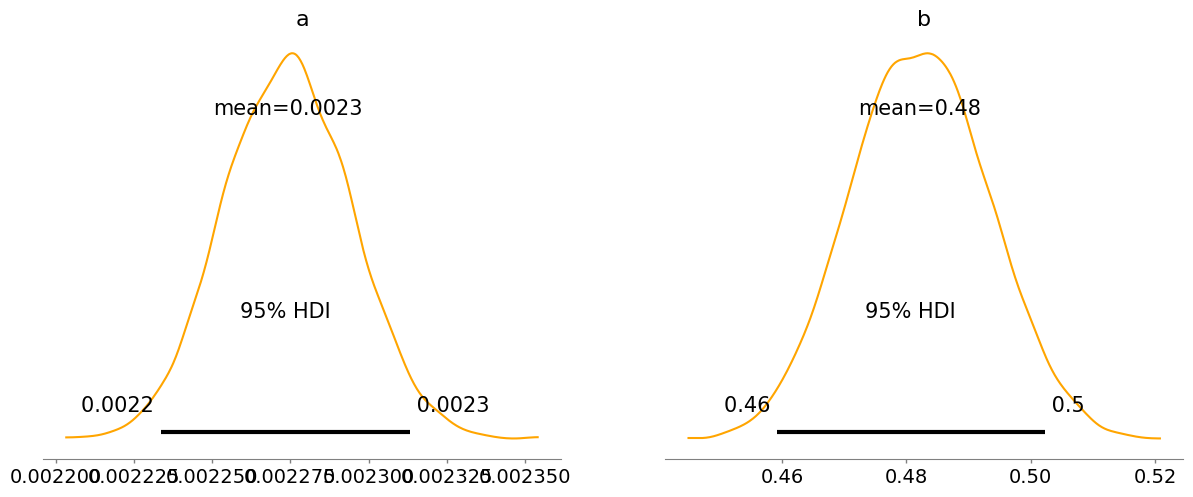

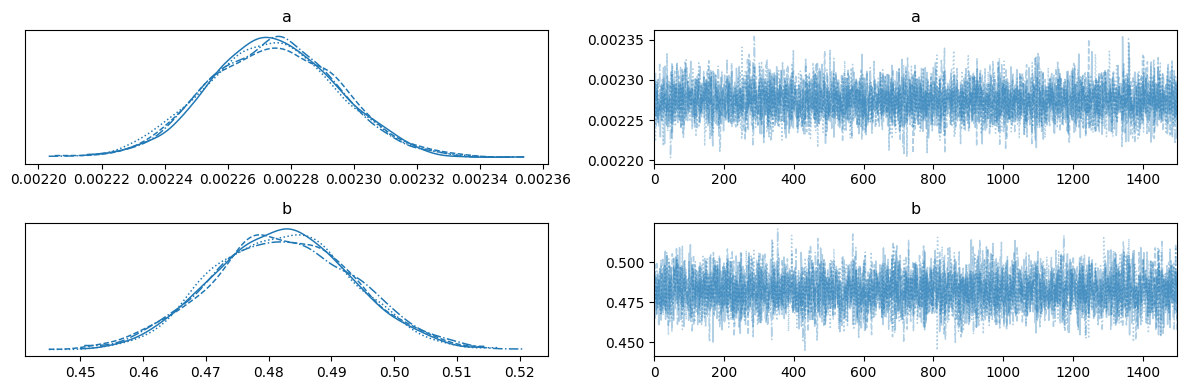

In [17]:
# GRÁFICO DE DISTRIBUCIONES POSTERIOREs
az.plot_posterior(
    idata,                  # Objeto con las muestras MCMC
    color="orange",
    var_names=["a", "b"],   # Parámetros a visualizar (tasa de transmisión y recuperación)
    hdi_prob=0.95           # Intervalo de Densidad de Alta Probabilidad del 95%
)

plt.show()

# GRÁFICO DE TRAZAS MCMC

az.plot_trace(
    idata,                  # Objeto con las muestras MCMC
    var_names=["a", "b"]    # Parámetros a diagnosticar
)

plt.tight_layout()

plt.show()

## **Comparación del modelo con los datos observados**

Esta gráfica es fundamental porque permite evaluar si el modelo SIR reproduce razonablemente la evolución del brote. Los puntos rosas son los infectados observados. La línea morada representa la predicción del modelo con las medias posteriores estimadas de a y b. Si la línea sigue de cerca los puntos, el modelo reproduce razonablemente la tendencia de los datos.

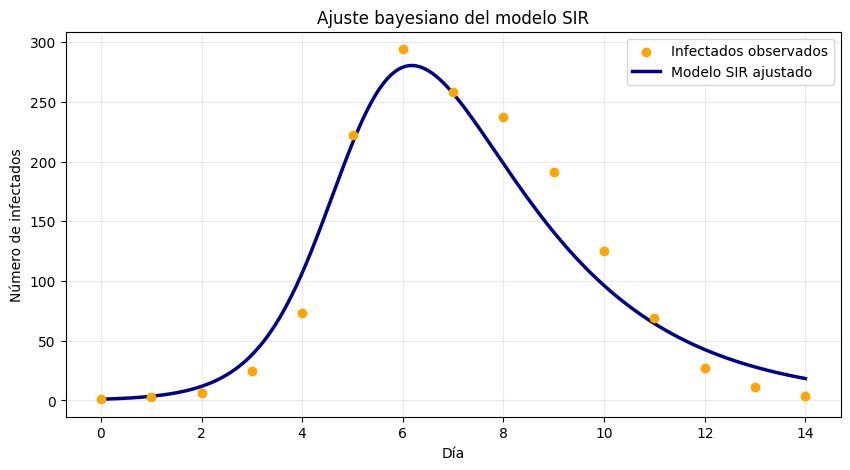

Estimación de a: 0.002274
Estimación de b: 0.482189


In [19]:
# EXTRACCIÓN DE LOS VALORES ESTIMADOS (MEDIAS POSTERIORES
a_estimado = float(idata.posterior["a"].mean().values)
b_estimado = float(idata.posterior["b"].mean().values)


# SIMULACIÓN DEL MODELO SIR CON LOS PARÁMETROS ESTIMADOS
def simular_sir(a, b, dt=0.01):
    S, I, R = float(S0), float(I0), float(R0)
    tiempos = [0.0]
    infectados = [I]

    # Iterar durante 14 días con el paso de tiempo definido
    for k in range(int(14 / dt)):
        # Nuevos contagios y recuperaciones en el intervalo dt (método de Euler)
        contagios = a * S * I * dt
        recuperaciones = b * I * dt

        # Actualizar el estado de cada compartimento
        S -= contagios
        I += contagios - recuperaciones
        R += recuperaciones

        # Registrar el tiempo y el número de infectados en este paso
        tiempos.append((k + 1) * dt)
        infectados.append(I)

    return np.array(tiempos), np.array(infectados)

tiempos, I_sim = simular_sir(a_estimado, b_estimado)

# COMPARACIÓN GRÁFICA: MODELO AJUSTADO VS DATOS OBSERVADOS

plt.figure(figsize=(10, 5))

plt.scatter(
    dias, I_datos,
    color="orange",
    label="Infectados observados",
    zorder=3
)

# Graficar la curva del modelo SIR ajustado
plt.plot(
    tiempos, I_sim,
    color="darkblue",
    linewidth=2.5,
    label="Modelo SIR ajustado"
)

plt.title("Ajuste bayesiano del modelo SIR")
plt.xlabel("Día")
plt.ylabel("Número de infectados")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

print(f"Estimación de a: {a_estimado:.6f}")
print(f"Estimación de b: {b_estimado:.6f}")

## **Gráfica de los Tres Compartimentos**

Se grafica la evolución de los tres compartimentos (S, I, R). Se espera que los susceptibles disminuyan, los infectados aumenten y luego disminuyan, y los recuperados aumenten. La suma de los tres grupos debe permanecer aproximadamente igual a $N$. El error numérico debe ser pequeño.

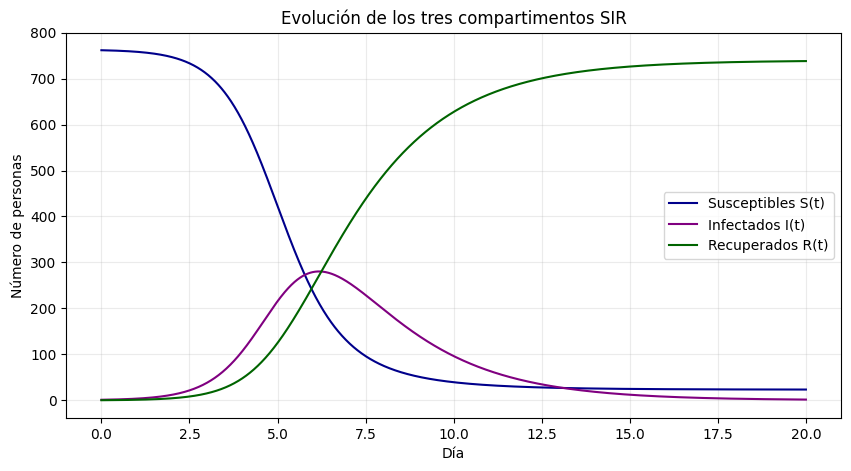

Error máximo de conservación: 0.0000000000


In [22]:
# FUNCIÓN PARA SIMULAR LOS TRES COMPARTIMENTOS DEL MODELO SIR

def simular_compartimentos(a, b, dt=0.01):
    S, I, R = float(S0), float(I0), float(R0)

    tiempos = [0.0]
    susceptibles = [S]
    infectados = [I]
    recuperados = [R]

    # Iterar durante 20 días con el paso de tiempo definido
    for k in range(int(20 / dt)):
        # Nuevos contagios y recuperaciones en el intervalo dt (método de Euler)
        contagios = a * S * I * dt
        recuperaciones = b * I * dt

        # Actualizar el estado de cada compartimento según las ecuaciones diferenciales
        S -= contagios
        I += contagios - recuperaciones
        R += recuperaciones

        # Registrar el tiempo y el estado de cada compartimento en este paso
        tiempos.append((k + 1) * dt)
        susceptibles.append(S)
        infectados.append(I)
        recuperados.append(R)

    return tiempos, susceptibles, infectados, recuperados

# Simular los tres compartimentos usando las medias posteriores de a y b
t, S_sim, I_sim, R_sim = simular_compartimentos(
    a_estimado, b_estimado
)

plt.figure(figsize=(10, 5))

plt.plot(t, S_sim, label="Susceptibles S(t)", color="darkblue")
plt.plot(t, I_sim, label="Infectados I(t)", color="purple")
plt.plot(t, R_sim, label="Recuperados R(t)", color="darkgreen")

# Personalización de la gráfica
plt.title("Evolución de los tres compartimentos SIR")
plt.xlabel("Día")
plt.ylabel("Número de personas")
plt.grid(alpha=0.25)
plt.legend()
plt.show()
# VERIFICACIÓN DE LA CONSERVACIÓN DE LA POBLACIÓN

error = np.max(
    np.abs(np.array(S_sim) + np.array(I_sim) +
           np.array(R_sim) - N)
)

print(f"Error máximo de conservación: {error:.10f}")

## **Conclusión**

Se estimo los parámetros de transmisión y recuperación de un brote epidémico mediante la integración del modelo matemático SIR y la inferencia bayesiana con PyMC. El sustento matemático basado en ecuaciones diferenciales, el teorema de Bayes y una verosimilitud de Poisson, permitió vincular la teoría con los datos observados y cuantificar la incertidumbre. Los resultados evidenciaron una correcta convergencia del muestreo MCMC, mientras que la comparación gráfica demostró que el modelo ajustado reproduce fielmente la tendencia real del brote (crecimiento, pico y descenso). Asimismo, la evolución de los compartimentos confirmó el comportamiento esperado y un error numérico mínimo en la conservación de la población